# Predicción de la dificultad de pago mediante modelos explicables

## Proyecto práctico de la Unidad 2 · Fase II

## <a id="indice"></a> Índice

- [0. Portada y objetivos](#sec-0)
  - [Datos del proyecto](#sec-0-datos-del-proyecto)
  - [Objetivo de predicción](#sec-0-objetivo-de-prediccion)
  - [Objetivos específicos](#sec-0-objetivos-especificos)
  - [Alcance](#sec-0-alcance)
  - [Guía del notebook](#sec-0-guia-del-notebook)
- [1. Entorno y reproducibilidad](#sec-1)
  - [1.1. Entorno de ejecución y dependencias](#sec-1-1)
  - [1.2. Importaciones, versiones y semillas](#sec-1-2)
  - [1.3. Localización y carga de archivos](#sec-1-3)
- [2. Descripción de los datos](#sec-2)
  - [2.1. Contexto y variable objetivo](#sec-2-1)
  - [2.2. Archivos y estructura](#sec-2-2)
  - [2.3. Diccionario de variables](#sec-2-3)
  - [2.4. Organización de los datos para el análisis](#sec-2-4)
- [3. Exploración y calidad de los datos](#sec-3)
  - [3.1. Distribución de la variable objetivo](#sec-3-1)
  - [3.2. Tipos de variables y valores ausentes](#sec-3-2)
  - [3.3. Identificadores y duplicados](#sec-3-3)
  - [3.4. Comprobaciones de dominio](#sec-3-4)
  - [3.5. Distribuciones de los predictores](#sec-3-5)
  - [3.6. Asociaciones y variables relacionadas](#sec-3-6)
  - [3.7. Revisión de posibles fugas de información](#sec-3-7)
  - [3.8. Síntesis de la exploración](#sec-3-8)
- [4. Diseño de la evaluación](#sec-4)
  - [4.1. Cinco particiones comunes](#sec-4-1)
  - [4.2. Métricas y criterio de selección](#sec-4-2)
  - [4.3. Referencia de la clase mayoritaria](#sec-4-3)
  - [4.4. Ajuste de configuraciones, variables y umbrales](#sec-4-4)
  - [4.5. Comparación y entrenamiento final](#sec-4-5)
- [5. Preprocesamiento](#sec-5)
  - [5.1. Decisiones de preprocesamiento](#sec-5-1)
  - [5.2. Codificación y escalado](#sec-5-2)
  - [5.3. Integración con los modelos](#sec-5-3)
  - [5.4. Comprobación en una partición](#sec-5-4)
  - [5.5. Uso en la validación cruzada](#sec-5-5)
- [6. Modelo lógico](#sec-6)
- [7. Regresión logística](#sec-7)
- [8. Explainable Boosting Machine](#sec-8)
- [9. Comparación del rendimiento](#sec-9)
- [10. Interpretación local comparada](#sec-10)
- [11. Discusión de las explicaciones](#sec-11)
- [12. Selección y entrenamiento final](#sec-12)
- [13. Predicción y exportación del test](#sec-13)
- [14. Conclusiones](#sec-14)
- [15. Referencias y uso de IA generativa](#sec-15)

## <a id="sec-0"></a> 0. Portada y objetivos

### <a id="sec-0-datos-del-proyecto"></a> Datos del proyecto

**Asignatura:** Inteligencia Artificial Explicable  
**Grupo:** 3  
**Repositorio:** [germansanchezz/iax-group-3](https://github.com/germansanchezz/iax-group-3)  
**Fecha de actualización:** 13 de octubre de 2026

**Integrantes:**

| Nombre | Correo electrónico |
| --- | --- |
| Damián Benasco Sánchez | d.benasco@alumnos.upm.es |
| Germán Sánchez Carmona | german.sanchez.carmona@alumnos.upm.es |
| Jorge Enrique Vega Ortiz | jorge.vega@alumnos.upm.es |

### <a id="sec-0-objetivo-de-prediccion"></a> Objetivo de predicción

Predecir la variable binaria `payment_difficulty_next_month`: **1 indica dificultad de pago en el mes siguiente y 0 indica ausencia de dificultad**, según el diccionario de datos. El propósito del proyecto es evaluar el rendimiento predictivo y comprender qué aprende cada modelo, explicar predicciones individuales y analizar coincidencias y discrepancias entre sus explicaciones.

### <a id="sec-0-objetivos-especificos"></a> Objetivos específicos

- Entrenar e interpretar las tres familias de modelos exigidas: un modelo lógico (árbol de decisión, lista de reglas o conjunto de reglas), una regresión logística y un modelo aditivo generalizado Explainable Boosting Machine (EBM) con `interactions=0`.
- Utilizar validación cruzada de cinco particiones para comparar modelos y seleccionar hiperparámetros, variables y umbrales de clasificación, con métricas elegidas y justificadas.
- Interpretar globalmente los modelos y comparar sus explicaciones locales sobre los mismos casos, incluyendo al menos un caso de cada clase.
- Examinar el equilibrio entre rendimiento, complejidad e interpretabilidad y distinguir las asociaciones aprendidas de las afirmaciones causales.
- Seleccionar una configuración mediante validación cruzada, entrenar el modelo final con todos los datos etiquetados y completar `test.csv` con una columna `predicted_class` de valores 0 o 1, conservando las filas y columnas originales.

### <a id="sec-0-alcance"></a> Alcance

Este notebook corresponde al proyecto completo de la Fase II descrito en [el enunciado](../project-statement-xai-2026.pdf). El análisis utilizará los datos etiquetados de `train.csv`, el conjunto sin etiquetas `test.csv` y las definiciones de `data-dictionary.xlsx`. La variable objetivo y algunas variables docentes son semisintéticas; las conclusiones se limitarán al ejercicio de predicción e interpretación y no se considerarán evidencia sobre una población real de crédito ni una política lista para su despliegue.

El notebook recogerá el análisis y la implementación reproducible, con ejecución de principio a fin en Google Colab. Los resultados y conclusiones se incorporarán cuando se completen las secciones correspondientes.

### <a id="sec-0-guia-del-notebook"></a> Guía del notebook

Las secciones 1–5 preparan el entorno, describen y exploran los datos, definen la evaluación y establecen el preprocesamiento. Las secciones 6–8 desarrollan e interpretan las tres familias de modelos. Las secciones 9–11 comparan el rendimiento, las explicaciones locales y sus limitaciones. Las secciones 12–13 seleccionan y entrenan el modelo final y exportan las predicciones del test. Las secciones 14–15 recogen las conclusiones, las referencias y el uso de IA generativa.


[Volver al índice](#indice)

## <a id="sec-1"></a> 1. Entorno y reproducibilidad

### <a id="sec-1-1"></a> 1.1. Entorno de ejecución y dependencias

El análisis se desarrolla en Python y está preparado para ejecutarse en un entorno local de Jupyter o en Google Colab. Se utilizan NumPy, pandas y SciPy para la manipulación de datos y el cálculo numérico; matplotlib para la visualización; scikit-learn e InterpretML para el entrenamiento y la interpretación de los modelos; y openpyxl para la lectura del diccionario de datos en Excel.

Las celdas deben ejecutarse en orden, desde un kernel limpio. La primera celda comprueba las dependencias e instala únicamente las ausentes. Las versiones de referencia identifican el entorno utilizado para verificar este apartado, mientras que el registro posterior recoge las versiones efectivamente utilizadas en cada ejecución.

Para reproducir una ejecución en otro entorno, se pueden instalar las versiones exactas del registro mediante `%pip install paquete==versión` y reiniciar el kernel antes de ejecutar el notebook completo. La instalación inicial requiere conexión a Internet.


In [1]:
import importlib
import subprocess
import sys
from importlib.metadata import PackageNotFoundError, version

REFERENCE_VERSIONS = {
    "numpy": "2.2.6",
    "pandas": "2.3.3",
    "scipy": "1.15.3",
    "matplotlib": "3.10.9",
    "scikit-learn": "1.7.2",
    "interpret": "0.7.8",
    "openpyxl": "3.1.5",
}

missing_dependencies = []
for package, reference_version in REFERENCE_VERSIONS.items():
    try:
        version(package)
    except PackageNotFoundError:
        missing_dependencies.append(f"{package}=={reference_version}")

if missing_dependencies:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing_dependencies]
    )
    importlib.invalidate_caches()
    print("Dependencias ausentes instaladas.")
else:
    print("Todas las dependencias están instaladas.")

Todas las dependencias están instaladas.


### <a id="sec-1-2"></a> 1.2. Importaciones, versiones y semillas

Se importan las clases necesarias para los modelos lógicos, la regresión logística y Explainable Boosting Machine. La regresión logística de InterpretML permite obtener explicaciones globales y locales. Se configura `InlineProvider` para visualizar las explicaciones dentro del notebook, tanto en Jupyter como en Google Colab.

`SEED = 42` se utilizará también como `random_state` en los modelos y particiones que lo admitan. `N_JOBS = 1` fija un único proceso para las operaciones que admitan este parámetro. Las semillas por sí solas no garantizan resultados idénticos entre versiones, plataformas o implementaciones; por ello se registra también el entorno.

In [2]:
import hashlib
import platform
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display
from sklearn.tree import DecisionTreeClassifier
from interpret import set_visualize_provider, show
from interpret.glassbox import (
    ClassificationTree,
    ExplainableBoostingClassifier,
    LogisticRegression,
)
from interpret.provider import InlineProvider

SEED = 42
N_JOBS = 1
random.seed(SEED)
np.random.seed(SEED)
set_visualize_provider(InlineProvider())

print(f"Python: {platform.python_version()}")
print(f"Plataforma: {platform.platform()}")
print(f"Semilla: {SEED} | Procesos: {N_JOBS}")

environment_versions = pd.DataFrame(
    [
        {
            "Paquete": package,
            "Versión instalada": version(package),
            "Versión de referencia": reference_version,
        }
        for package, reference_version in REFERENCE_VERSIONS.items()
    ]
)
display(environment_versions)

# Registro de versiones exactas para repetir esta ejecución.
print("Dependencias de esta ejecución:")
print("\n".join(f"{package}=={version(package)}" for package in REFERENCE_VERSIONS))

Python: 3.10.21
Plataforma: Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.43
Semilla: 42 | Procesos: 1


,Paquete,Versión instalada,Versión de referencia
0,numpy,2.2.6,2.2.6
1,pandas,2.3.3,2.3.3
2,scipy,1.15.3,1.15.3
3,matplotlib,3.10.9,3.10.9
4,scikit-learn,1.7.2,1.7.2
5,interpret,0.7.8,0.7.8
6,openpyxl,3.1.5,3.1.5


Dependencias de esta ejecución:
numpy==2.2.6
pandas==2.3.3
scipy==1.15.3
matplotlib==3.10.9
scikit-learn==1.7.2
interpret==0.7.8
openpyxl==3.1.5


### <a id="sec-1-3"></a> 1.3. Localización y carga de archivos

Se necesitan `train.csv`, `test.csv` y `data-dictionary.xlsx`. En el repositorio se buscan en `data/`, tanto si el kernel se inicia en la raíz como en `notebooks/`. También se admite que los tres archivos estén en el directorio de ejecución.

En Google Colab, si no se encuentran los archivos, se abrirá el selector para subir los tres. Si están en Google Drive, montar primero la unidad con `from google.colab import drive; drive.mount('/content/drive')` y establecer `DATA_DIR_OVERRIDE` con la ruta de su carpeta. La ruta explícita tiene prioridad; si está incompleta, se mostrará qué archivos faltan.

Se cargan los CSV en `train_raw` y `test_raw`, y todas las hojas del Excel en `dictionary_sheets`. Se conserva `row_id` como texto para mantener los identificadores. En este apartado no se transforman las variables ni se ajustan modelos. La tabla de archivos registra su tamaño y huella SHA-256 para comprobar que distintas ejecuciones utilizan los mismos datos.

In [3]:
# Ejemplo en Drive: Path("/content/drive/MyDrive/proyecto_xai/data")
DATA_DIR_OVERRIDE = None
REQUIRED_FILES = ("train.csv", "test.csv", "data-dictionary.xlsx")

if DATA_DIR_OVERRIDE is not None:
    data_dir = Path(DATA_DIR_OVERRIDE).expanduser().resolve()
else:
    working_dir = Path.cwd().resolve()
    candidates = [working_dir / "data", working_dir.parent / "data", working_dir]
    data_dir = next(
        (directory for directory in candidates
         if all((directory / name).is_file() for name in REQUIRED_FILES)),
        None,
    )
    if data_dir is None and "google.colab" in sys.modules:
        from google.colab import files

        print("Sube train.csv, test.csv y data-dictionary.xlsx.")
        uploaded_files = files.upload()
        data_dir = working_dir

if data_dir is None:
    raise FileNotFoundError(
        "No se encontró una carpeta con los tres archivos. "
        "Establece DATA_DIR_OVERRIDE con la ruta de la carpeta de datos."
    )

missing_files = [name for name in REQUIRED_FILES if not (data_dir / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Faltan archivos en {data_dir}: {', '.join(missing_files)}")

train_raw = pd.read_csv(data_dir / "train.csv", dtype={"row_id": "string"})
test_raw = pd.read_csv(data_dir / "test.csv", dtype={"row_id": "string"})
dictionary_sheets = pd.read_excel(
    data_dir / "data-dictionary.xlsx", sheet_name=None, engine="openpyxl"
)

file_manifest = pd.DataFrame(
    [
        {
            "Archivo": name,
            "Bytes": (data_dir / name).stat().st_size,
            "SHA-256": hashlib.sha256((data_dir / name).read_bytes()).hexdigest(),
        }
        for name in REQUIRED_FILES
    ]
)
print(f"Carpeta de datos: {data_dir}")
display(file_manifest)
print(f"train_raw: {train_raw.shape[0]} filas × {train_raw.shape[1]} columnas")
print(f"test_raw: {test_raw.shape[0]} filas × {test_raw.shape[1]} columnas")
print(f"Hojas del diccionario: {', '.join(dictionary_sheets)}")

Carpeta de datos: /home/german/master-ia/iax/iax-group-3/data


,Archivo,Bytes,SHA-256
0,train.csv,2202681,80abfae992397f7869cb712ed7aef11988a584fe0edc0b...
1,test.csv,430761,1d07915ab453c8bf1e174647e358ae041e36ec6596826a...
2,data-dictionary.xlsx,10469,bebaedc4e865295d983cbae46356039852379b78575db1...


train_raw: 25000 filas × 17 columnas
test_raw: 5000 filas × 16 columnas
Hojas del diccionario: Data dictionary, Domain context


[Volver al índice](#indice)

## <a id="sec-2"></a> 2. Descripción de los datos

### <a id="sec-2-1"></a> 2.1. Contexto y variable objetivo

Los datos describen registros de clientes de una cartera de crédito: límite de crédito, características demográficas y resúmenes de facturación, pagos y retrasos durante los seis meses anteriores al mes del resultado. Según [el diccionario de datos](../data/data-dictionary.xlsx), la fuente original es *Default of Credit Card Clients*, de Yeh y Lien, disponible en UCI (DOI: `10.24432/C55S3H`). La variable objetivo y algunas variables del ejercicio son semisintéticas; por tanto, no debe equipararse este conjunto con la versión original de UCI.

La tarea es una **clasificación binaria** de `payment_difficulty_next_month`:

- **Clase 0:** ausencia de dificultad de pago en el mes siguiente.
- **Clase 1:** presencia de dificultad de pago en el mes siguiente.

La clase 1 se considera la clase positiva. El objetivo es anticipar el resultado del mes siguiente a partir de información anterior a ese resultado. Cada fila representa un registro identificado por `row_id`; el diccionario no permite afirmar que haya un único registro por persona.

Los resultados describirán asociaciones predictivas dentro de este conjunto semisintético. No identificarán efectos causales ni constituirán evidencia suficiente para implantar una política de crédito.

### <a id="sec-2-2"></a> 2.2. Archivos y estructura

`train.csv` contiene los registros etiquetados para desarrollar, comparar y entrenar los modelos. `test.csv` contiene registros sin la variable objetivo y se reserva para producir las predicciones finales. El diccionario Excel incluye las hojas `Data dictionary`, con las definiciones de variables, y `Domain context`, con su contexto temporal y las precauciones de interpretación.

La siguiente celda calcula los tamaños a partir de los archivos cargados en el apartado 1 y comprueba la estructura básica: presencia del identificador y del objetivo en entrenamiento, ausencia del objetivo en test y coincidencia de las columnas predictoras. La calidad de los valores y la distribución de clases se estudiarán en el apartado 3.

In [4]:
TARGET = "payment_difficulty_next_month"
ID_COLUMN = "row_id"
PREDICTION_COLUMN = "predicted_class"

for name, frame in (("train.csv", train_raw), ("test.csv", test_raw)):
    if ID_COLUMN not in frame.columns:
        raise ValueError(f"Falta {ID_COLUMN} en {name}.")
if TARGET not in train_raw.columns:
    raise ValueError(f"Falta la variable objetivo {TARGET} en train.csv.")
if TARGET in test_raw.columns:
    raise ValueError("Se esperaba un test sin la variable objetivo.")
if PREDICTION_COLUMN in train_raw.columns or PREDICTION_COLUMN in test_raw.columns:
    raise ValueError("Utiliza los archivos originales, sin la columna de predicciones.")

feature_columns = [
    column for column in train_raw.columns if column not in (ID_COLUMN, TARGET)
]
test_feature_columns = [column for column in test_raw.columns if column != ID_COLUMN]
if set(feature_columns) != set(test_feature_columns):
    raise ValueError("Las columnas predictoras de entrenamiento y test no coinciden.")

# Los tamaños se obtienen de los archivos, sin fijarlos manualmente.
dataset_summary = pd.DataFrame(
    [
        {
            "Archivo": name,
            "Filas": len(frame),
            "Columnas totales": frame.shape[1],
            "Predictores candidatos": len(feature_columns),
            "Identificador": ID_COLUMN,
            "Variable objetivo": TARGET if TARGET in frame.columns else "No incluida",
            "Uso": purpose,
        }
        for name, frame, purpose in (
            ("train.csv", train_raw, "Desarrollo, validación cruzada y entrenamiento final"),
            ("test.csv", test_raw, "Predicción final; sin etiquetas para evaluar"),
        )
    ]
)
display(dataset_summary)
print("Hojas del diccionario:", ", ".join(dictionary_sheets))

,Archivo,Filas,Columnas totales,Predictores candidatos,Identificador,Variable objetivo,Uso
0,train.csv,25000,17,15,row_id,payment_difficulty_next_month,"Desarrollo, validación cruzada y entrenamiento..."
1,test.csv,5000,16,15,row_id,No incluida,Predicción final; sin etiquetas para evaluar


Hojas del diccionario: Data dictionary, Domain context


La vista de las primeras filas permite reconocer cómo se representan las variables en los CSV. Es una muestra de la estructura, no un resumen estadístico del conjunto.

In [5]:
print("Primeras filas del conjunto etiquetado:")
display(train_raw.head())
print("Primeras filas del conjunto sin etiquetas:")
display(test_raw.head())

Primeras filas del conjunto etiquetado:


,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan,payment_difficulty_next_month
0,CR26-120473,80000,male,university,married,54,0,0,0,24600,3700,10300,0.07,0,0.33,no,0
1,CR26-127004,20000,male,university,single,30,0,0,0,21100,21000,6700,0.05,0,1.98,no,0
2,CR26-116408,230000,female,graduate_school,married,35,0,0,0,1700,3600,5100,0.49,1,0.03,no,0
3,CR26-125768,150000,female,university,married,51,0,0,0,76100,-8800,15400,0.03,0,0.48,no,0
4,CR26-118040,500000,male,graduate_school,married,43,0,0,0,121600,26200,25000,0.03,0,0.25,yes,0


Primeras filas del conjunto sin etiquetas:


,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan
0,CR26-128173,50000,male,graduate_school,single,25,0,0,0,27700,31600,21700,0.13,0,0.80,no
1,CR26-102911,280000,female,university,married,41,1,1,1,100,300,600,0.63,4,0.00,no
2,CR26-104960,420000,male,university,married,38,0,0,0,262500,108200,56200,0.04,0,0.70,no
3,CR26-123913,270000,male,university,single,44,0,0,0,247400,48900,56400,0.04,0,1.02,no
4,CR26-111750,120000,female,graduate_school,single,29,-1,0,0,1700,-2100,12000,1.20,0,0.00,yes


### <a id="sec-2-3"></a> 2.3. Diccionario de variables

La siguiente tabla resume las definiciones del diccionario proporcionado. **NTD** corresponde al dólar taiwanés. Los tipos descritos son semánticos: una variable almacenada como número puede representar un código y no una magnitud continua.

| Variable | Papel y tipo | Significado y observaciones |
| --- | --- | --- |
| `row_id` | Identificador, texto | Identificador opaco para alinear los registros y las predicciones. Se conserva para la exportación y se excluye de los predictores. |
| `credit_limit` | Predictor, entero | Límite de crédito registrado, en NTD. |
| `sex` | Predictor y atributo de auditoría, categórica | Sexo registrado: `female` o `male`. La fuente solo recoge estas dos categorías. Permite una auditoría descriptiva de subgrupos; su inclusión como predictor deberá justificarse. |
| `education` | Predictor, categórica | Grupo de educación registrado. Los códigos no documentados se agrupan en `unknown`. |
| `marital_status` | Predictor, categórica | Estado civil registrado. Los códigos no documentados y otras categorías se agrupan en `other_or_unknown`. |
| `age` | Predictor, entero | Edad en años en el momento del registro de crédito. |
| `latest_repayment_status` | Predictor, código entero | Estado de pago más reciente. Los valores positivos indican meses de retraso; no se atribuirá un significado específico a los códigos negativos o cero, que no están completamente documentados. |
| `maximum_repayment_delay_6m` | Predictor, entero | Máximo retraso positivo durante seis meses, en meses. Los códigos de estado no positivos contribuyen con cero al agregado. |
| `delayed_months_6m` | Predictor, entero | Número de meses con código de retraso positivo durante seis meses; rango de 0 a 6. |
| `average_bill_6m` | Predictor, entero | Facturación media durante seis meses, en NTD, redondeada a centenas. |
| `bill_change_sep_to_apr` | Predictor, entero | Factura de septiembre menos factura de abril, en NTD, redondeada a centenas. Un valor positivo indica mayor facturación en septiembre. |
| `total_payment_6m` | Predictor, entero | Total pagado durante seis meses, en NTD, redondeado a centenas. |
| `payment_to_bill_ratio_6m` | Predictor, real | Total pagado en seis meses dividido por la suma de las facturas positivas. El denominador tiene un mínimo de 1.000 NTD y el cociente un máximo de 5. Valores altos pueden reflejar pagos extraordinarios o facturas pequeñas; no se presupone una relación lineal con el riesgo. |
| `zero_payment_months_6m` | Predictor, entero | Número de meses con pago registrado igual a cero durante seis meses; rango de 0 a 6. Un mes sin pago no tiene necesariamente la misma implicación que varios meses consecutivos o repetidos. |
| `utilization_sep` | Predictor, real | Factura de septiembre dividida por el límite de crédito. Se limita al intervalo de 0 a 2 y se redondea a dos decimales. |
| `repayment_assistance_plan` | Predictor, categórica | Registro de un plan temporal de apoyo al pago o reestructuración anterior al mes del resultado. Su asignación es selectiva y puede responder a signos previos de dificultad financiera. |
| `payment_difficulty_next_month` | Objetivo, binaria | Indicador semisintético de dificultad de pago en el mes siguiente: 1 significa sí y 0 significa no. Solo se incluye en entrenamiento. |
| `predicted_class` | Salida de entrega, binaria | Etiqueta predicha, con valores 0 o 1, que se añadirá al test en la exportación final. No es una variable de entrada. |

La siguiente celda vincula los nombres presentes en los CSV con el diccionario y muestra el tipo de almacenamiento detectado por pandas junto al tipo semántico documentado. El diccionario incluye `predicted_class`, aunque esta columna todavía no está en los archivos originales.

In [6]:
data_dictionary = dictionary_sheets["Data dictionary"].copy()
required_dictionary_columns = {"variable", "role", "type", "units", "description", "notes"}
if not required_dictionary_columns.issubset(data_dictionary.columns):
    raise ValueError("El diccionario no contiene las columnas esperadas.")

undocumented_columns = set(train_raw.columns) - set(data_dictionary["variable"])
if undocumented_columns:
    raise ValueError(f"Variables no documentadas: {sorted(undocumented_columns)}")

variable_schema = data_dictionary[["variable", "role", "type", "units"]].copy()
variable_schema["En entrenamiento"] = variable_schema["variable"].isin(train_raw.columns)
variable_schema["En test original"] = variable_schema["variable"].isin(test_raw.columns)
variable_schema["Tipo en pandas (train)"] = variable_schema["variable"].map(
    train_raw.dtypes.astype(str).to_dict()
).fillna("No incluida")
variable_schema = variable_schema.rename(
    columns={"variable": "Variable", "role": "Papel documentado",
             "type": "Tipo semántico", "units": "Unidad"}
)
variable_schema["Unidad"] = variable_schema["Unidad"].fillna("No aplicable")
display(variable_schema)

,Variable,Papel documentado,Tipo semántico,Unidad,En entrenamiento,En test original,Tipo en pandas (train)
0,row_id,identifier,text,No aplicable,True,True,string
1,credit_limit,predictor,integer,NTD,True,True,int64
2,sex,predictor / audit attribute,categorical,No aplicable,True,True,object
3,education,predictor,categorical,No aplicable,True,True,object
4,marital_status,predictor,categorical,No aplicable,True,True,object
5,age,predictor,integer,years,True,True,int64
6,latest_repayment_status,predictor,integer code,No aplicable,True,True,int64
7,maximum_repayment_delay_6m,predictor,integer,months,True,True,int64
8,delayed_months_6m,predictor,integer,months,True,True,int64
9,average_bill_6m,predictor,integer,NTD,True,True,int64


### <a id="sec-2-4"></a> 2.4. Organización de los datos para el análisis

Se separan los predictores candidatos (`X_raw`), las etiquetas (`y`) y los predictores del test (`X_test_raw`). Se excluyen `row_id` y la variable objetivo de las entradas de los modelos, y se conserva el mismo orden de columnas predictoras en ambos conjuntos. Los identificadores del test se guardan por separado para comprobar la alineación durante la exportación. Esta separación no aplica imputación, codificación, escalado ni selección de variables.

El contexto temporal distingue los seis meses de comportamiento previo, el posible plan de asistencia anterior al resultado y la dificultad de pago del mes siguiente. Que el plan de asistencia se asocie con mayor riesgo no implica que lo cause: puede ofrecerse precisamente a clientes que ya muestran dificultades. Asimismo, comparar errores entre categorías de `sex` permitirá describir diferencias, pero no bastará por sí solo para establecer equidad o inequidad.

El test no proporciona etiquetas con las que calcular métricas. Las decisiones sobre modelos, variables, hiperparámetros y umbrales se basarán en la validación cruzada del conjunto etiquetado. La distribución de clases, los valores ausentes, los duplicados y las posibles fugas de información se examinarán en el siguiente apartado.

In [7]:
X_raw = train_raw.loc[:, feature_columns].copy()
y = train_raw[TARGET].copy()
X_test_raw = test_raw.loc[:, feature_columns].copy()
test_row_ids = test_raw[ID_COLUMN].copy()

print(f"X_raw: {X_raw.shape} | y: {y.shape}")
print(f"X_test_raw: {X_test_raw.shape}")
print("Predictores candidatos:", ", ".join(feature_columns))

X_raw: (25000, 15) | y: (25000,)
X_test_raw: (5000, 15)
Predictores candidatos: credit_limit, sex, education, marital_status, age, latest_repayment_status, maximum_repayment_delay_6m, delayed_months_6m, average_bill_6m, bill_change_sep_to_apr, total_payment_6m, payment_to_bill_ratio_6m, zero_payment_months_6m, utilization_sep, repayment_assistance_plan


[Volver al índice](#indice)

## <a id="sec-3"></a> 3. Exploración y calidad de los datos

La exploración busca conocer la distribución de clases, detectar problemas de calidad y reconocer patrones que puedan afectar al entrenamiento o a la interpretación. El análisis de distribuciones y asociaciones se realiza sobre el conjunto etiquetado. El test se utiliza aquí únicamente para comprobar su integridad y compatibilidad con entrenamiento, sin orientar la selección de modelos o transformaciones.

### <a id="sec-3-1"></a> 3.1. Distribución de la variable objetivo

Se comprueba que todas las etiquetas estén presentes y sean 0 o 1. La tabla y el gráfico muestran cuántos registros pertenecen a cada clase. La proporción mayoritaria permite contextualizar la exactitud: un clasificador que siempre predijera esa clase obtendría esa exactitud en estos datos, aunque no detectaría ningún caso de la otra clase. Las métricas de evaluación se definirán en el apartado 4.

,Registros,Porcentaje
Clase,,
0,19697,78.79
1,5303,21.21


Exactitud de predecir siempre la clase mayoritaria: 78.79%


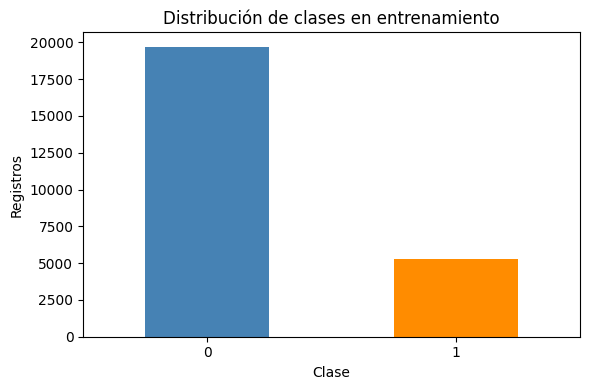

In [8]:
if y.isna().any() or not y.isin([0, 1]).all():
    raise ValueError("La variable objetivo contiene etiquetas ausentes o distintas de 0 y 1.")

class_counts = y.value_counts().reindex([0, 1], fill_value=0)
class_summary = pd.DataFrame({
    "Registros": class_counts,
    "Porcentaje": (class_counts / len(y) * 100).round(2),
})
class_summary.index.name = "Clase"
display(class_summary)
print(f"Exactitud de predecir siempre la clase mayoritaria: {class_counts.max() / len(y):.2%}")

ax = class_counts.plot.bar(color=["steelblue", "darkorange"], rot=0, figsize=(6, 4))
ax.set(title="Distribución de clases en entrenamiento", xlabel="Clase", ylabel="Registros")
plt.tight_layout()
plt.show()

La comprobación confirma que las etiquetas son válidas y están completas. De los 25.000 registros, **19.697 pertenecen a la clase 0 (78,79 %) y 5.303 a la clase 1 (21,21 %)**. Existe desequilibrio de clases: predecir siempre 0 alcanzaría un 78,79 % de exactitud en este conjunto sin detectar ningún caso de dificultad de pago. Por ello, la evaluación deberá considerar también la capacidad de reconocer la clase positiva y el comportamiento en ambas clases.

### <a id="sec-3-2"></a> 3.2. Tipos de variables y valores ausentes

Se identifican las variables numéricas y categóricas según su almacenamiento en pandas. Esta clasificación inicial se interpreta junto al diccionario: `latest_repayment_status` es un código entero, y las variables de recuento tienen dominios discretos.

La tabla de calidad muestra, para cada columna de ambos archivos, su tipo, número de valores distintos y valores ausentes. Los niveles `unknown` y `other_or_unknown` son categorías documentadas, no valores ausentes de pandas; su frecuencia se mostrará en la exploración categórica. También se comprueba la presencia de valores infinitos en los predictores numéricos.

In [9]:
numeric_features = X_raw.select_dtypes(include="number").columns.tolist()
categorical_features = [column for column in feature_columns if column not in numeric_features]

print("Variables numéricas:", ", ".join(numeric_features))
print("Variables categóricas:", ", ".join(categorical_features))

quality_tables = []
for name, frame in (("train.csv", train_raw), ("test.csv", test_raw)):
    quality = pd.DataFrame({
        "Tipo": frame.dtypes.astype(str),
        "Valores distintos (sin ausentes)": frame.nunique(),
        "Ausentes": frame.isna().sum(),
        "Ausentes (%)": (frame.isna().mean() * 100).round(2),
    })
    quality["Infinitos"] = 0
    quality.loc[numeric_features, "Infinitos"] = np.isinf(frame[numeric_features]).sum()
    quality_tables.append(quality)

quality_summary = pd.concat(quality_tables, keys=["train.csv", "test.csv"], names=["Archivo", "Variable"])
display(quality_summary)

Variables numéricas: credit_limit, age, latest_repayment_status, maximum_repayment_delay_6m, delayed_months_6m, average_bill_6m, bill_change_sep_to_apr, total_payment_6m, payment_to_bill_ratio_6m, zero_payment_months_6m, utilization_sep
Variables categóricas: sex, education, marital_status, repayment_assistance_plan


Tipo  \
Archivo   Variable                                 
train.csv row_id                          string   
          credit_limit                     int64   
          sex                             object   
          education                       object   
          marital_status                  object   
          age                              int64   
          latest_repayment_status          int64   
          maximum_repayment_delay_6m       int64   
          delayed_months_6m                int64   
          average_bill_6m                  int64   
          bill_change_sep_to_apr           int64   
          total_payment_6m                 int64   
          payment_to_bill_ratio_6m       float64   
          zero_payment_months_6m           int64   
          utilization_sep                float64   
          repayment_assistance_plan       object   
          payment_difficulty_next_month    int64   
test.csv  row_id                          string   
          credit_limit                     int64   
          sex                             object   
          education                       object   
          marital_status                  object   
          age                              int64   
          latest_repayment_status          int64   
          maximum_repayment_delay_6m       int64   
          delayed_months_6m                int64   
          average_bill_6m                  int64   
          bill_change_sep_to_apr           int64   
          total_payment_6m                 int64   
          payment_to_bill_ratio_6m       float64   
          zero_payment_months_6m           int64   
          utilization_sep                float64   
          repayment_assistance_plan       object   

                                         Valores distintos (sin ausentes)  \
Archivo   Variable                                                          
train.csv row_id                                                    25000   
          credit_limit                                                 80   
          sex                                                           2   
          education                                                     5   
          marital_status                                                3   
          age                                                          56   
          latest_repayment_status                                      11   
          maximum_repayment_delay_6m                                    9   
          delayed_months_6m                                             7   
          average_bill_6m                                            2592   
          bill_change_sep_to_apr                                     2549   
          total_payment_6m                                           2055   
          payment_to_bill_ratio_6m                                    349   
          zero_payment_months_6m                                        7   
          utilization_sep                                             195   
          repayment_assistance_plan                                     2   
          payment_difficulty_next_month                                 2   
test.csv  row_id                                                     5000   
          credit_limit                                                 69   
          sex                                                           2   
          education                                                     5   
          marital_status                                                3   
          age                                                          52   
          latest_repayment_status                                      11   
          maximum_repayment_delay_6m                                    9   
          delayed_months_6m                                             7   
          average_bill_6m                                          

Los 15 predictores se distribuyen en **11 variables numéricas y 4 categóricas**. No se detectan valores ausentes en ninguna columna de entrenamiento o test, ni infinitos en los predictores numéricos. Estos archivos no requieren corregir ausentes observados; si se incluye imputación en el pipeline, deberá explicarse su finalidad. Los códigos `unknown` y `other_or_unknown` permanecen como categorías explícitas y no se confunden con valores nulos.

### <a id="sec-3-3"></a> 3.3. Identificadores y duplicados

Se distinguen filas completamente duplicadas, identificadores repetidos y perfiles con los mismos predictores. Los conteos de duplicados indican repeticiones posteriores a la primera aparición. Dos registros con los mismos predictores no demuestran que correspondan a la misma persona; no se eliminarán automáticamente.

Se comprueba además si hay identificadores compartidos entre entrenamiento y test y si un mismo perfil de predictores aparece con etiquetas diferentes. Los identificadores compartidos o repetidos requerirían revisar la separación de los conjuntos. Los perfiles repetidos requerirían valorar si pueden aparecer a ambos lados de una partición de validación; las etiquetas diferentes no implican necesariamente un error, pues la información disponible puede ser insuficiente para determinar el resultado.

In [10]:
duplicate_summary = pd.DataFrame([
    {
        "Archivo": name,
        "Filas duplicadas completas": int(frame.duplicated().sum()),
        "Identificadores repetidos (sin ausentes)": int(frame[ID_COLUMN].dropna().duplicated().sum()),
        "Perfiles de predictores repetidos": int(frame.duplicated(subset=feature_columns).sum()),
    }
    for name, frame in (("train.csv", train_raw), ("test.csv", test_raw))
])
display(duplicate_summary)

shared_ids = set(train_raw[ID_COLUMN].dropna()) & set(test_raw[ID_COLUMN].dropna())
labels_per_profile = train_raw.groupby(feature_columns, dropna=False)[TARGET].nunique()
print("Identificadores distintos compartidos entre train y test:", len(shared_ids))
print("Perfiles con etiquetas diferentes:", int((labels_per_profile > 1).sum()))

,Archivo,Filas duplicadas completas,Identificadores repetidos (sin ausentes),Perfiles de predictores repetidos
0,train.csv,0,0,31
1,test.csv,0,0,0


Identificadores distintos compartidos entre train y test: 0
Perfiles con etiquetas diferentes: 13


No hay filas completas duplicadas ni identificadores repetidos en ninguno de los conjuntos, y no hay identificadores compartidos entre entrenamiento y test. En entrenamiento se detectan **31 repeticiones de perfiles de predictores posteriores a su primera aparición**; esta cifra no representa 31 personas duplicadas ni necesariamente 31 perfiles distintos. El test no presenta repeticiones de perfiles dentro de su propio conjunto.

Además, **13 perfiles distintos aparecen con etiquetas diferentes**. Esto indica que los predictores disponibles no determinan de forma única todas las etiquetas observadas; no basta para afirmar que sean errores de etiquetado. Se conservan los registros. En el diseño de la evaluación deberá valorarse la presencia de perfiles repetidos, sin asumir que pertenezcan a la misma persona. Esta comprobación no ha contrastado la coincidencia de perfiles entre entrenamiento y test.

### <a id="sec-3-4"></a> 3.4. Comprobaciones de dominio

Se revisan los límites expresamente documentados: recuentos de meses entre 0 y 6, cociente de pagos entre 0 y 5 y utilización entre 0 y 2. Los recuentos de meses deben ser enteros, y el retraso máximo debe ser un entero no negativo. Se comprueban también las categorías documentadas de `sex`. Los valores ausentes se contabilizan en la tabla anterior y no se cuentan como incumplimientos de dominio.

No se consideran errores los códigos negativos de `latest_repayment_status`, los importes negativos de facturación ni los valores extremos por el mero hecho de ser poco frecuentes. Su interpretación exige atender al significado de cada variable. Esta revisión tampoco certifica la calidad completa del conjunto: comprueba solo las condiciones indicadas.

In [11]:
bounded_domains = {
    "delayed_months_6m": (0, 6),
    "zero_payment_months_6m": (0, 6),
    "payment_to_bill_ratio_6m": (0, 5),
    "utilization_sep": (0, 2),
}
integer_counts = ["delayed_months_6m", "zero_payment_months_6m", "maximum_repayment_delay_6m"]
domain_results = []
for name, frame in (("train.csv", train_raw), ("test.csv", test_raw)):
    for column, (lower, upper) in bounded_domains.items():
        values = frame[column].dropna()
        domain_results.append({"Archivo": name, "Variable": column,
                               "Comprobación": f"Intervalo [{lower}, {upper}]",
                               "Incumplimientos": int((~values.between(lower, upper)).sum())})
    for column in integer_counts:
        values = frame[column].dropna()
        invalid = (values < 0) | (values % 1 != 0)
        domain_results.append({"Archivo": name, "Variable": column,
                               "Comprobación": "Entero no negativo",
                               "Incumplimientos": int(invalid.sum())})
    invalid_sex = frame["sex"].notna() & ~frame["sex"].isin(["female", "male"])
    domain_results.append({"Archivo": name, "Variable": "sex",
                           "Comprobación": "female o male",
                           "Incumplimientos": int(invalid_sex.sum())})

domain_summary = pd.DataFrame(domain_results)
display(domain_summary)

,Archivo,Variable,Comprobación,Incumplimientos
0,train.csv,delayed_months_6m,"Intervalo [0, 6]",0
1,train.csv,zero_payment_months_6m,"Intervalo [0, 6]",0
2,train.csv,payment_to_bill_ratio_6m,"Intervalo [0, 5]",0
3,train.csv,utilization_sep,"Intervalo [0, 2]",0
4,train.csv,delayed_months_6m,Entero no negativo,0
5,train.csv,zero_payment_months_6m,Entero no negativo,0
6,train.csv,maximum_repayment_delay_6m,Entero no negativo,0
7,train.csv,sex,female o male,0
8,test.csv,delayed_months_6m,"Intervalo [0, 6]",0
9,test.csv,zero_payment_months_6m,"Intervalo [0, 6]",0


Todas las comprobaciones de dominio arrojan **cero incumplimientos** en entrenamiento y test. Los recuentos revisados son enteros no negativos y las variables acotadas respetan los intervalos documentados. No se identifica ninguna corrección necesaria a partir de estas reglas; el resultado no certifica la ausencia de otros problemas de calidad.

### <a id="sec-3-5"></a> 3.5. Distribuciones de los predictores

El resumen numérico muestra los rangos y las diferencias de escala; los histogramas permiten observar asimetrías, concentraciones y valores extremos. En variables discretas, las barras deben interpretarse como agrupaciones de valores, no como evidencia de continuidad. Estos gráficos no justifican por sí solos recortar valores o suponer una relación lineal con la dificultad de pago.

,count,mean,std,min,25%,50%,75%,max
credit_limit,25000.0,167740.95,129975.98,10000.0,50000.00,140000.00,240000.00,1000000.0
age,25000.0,35.50,9.24,21.0,28.00,34.00,41.00,79.0
latest_repayment_status,25000.0,-0.02,1.12,-2.0,-1.00,0.00,0.00,8.0
maximum_repayment_delay_6m,25000.0,0.68,1.07,0.0,0.00,0.00,2.00,8.0
delayed_months_6m,25000.0,0.83,1.55,0.0,0.00,0.00,1.00,6.0
average_bill_6m,25000.0,44910.44,63267.26,-56000.0,4700.00,21000.00,57100.00,877300.0
bill_change_sep_to_apr,25000.0,12389.51,44068.85,-403600.0,-3000.00,900.00,19900.00,708300.0
total_payment_6m,25000.0,31635.05,57337.82,0.0,6700.00,14400.00,33700.00,2314200.0
payment_to_bill_ratio_6m,25000.0,0.37,0.59,0.0,0.04,0.09,0.60,5.0
zero_payment_months_6m,25000.0,1.23,1.72,0.0,0.00,0.00,2.00,6.0


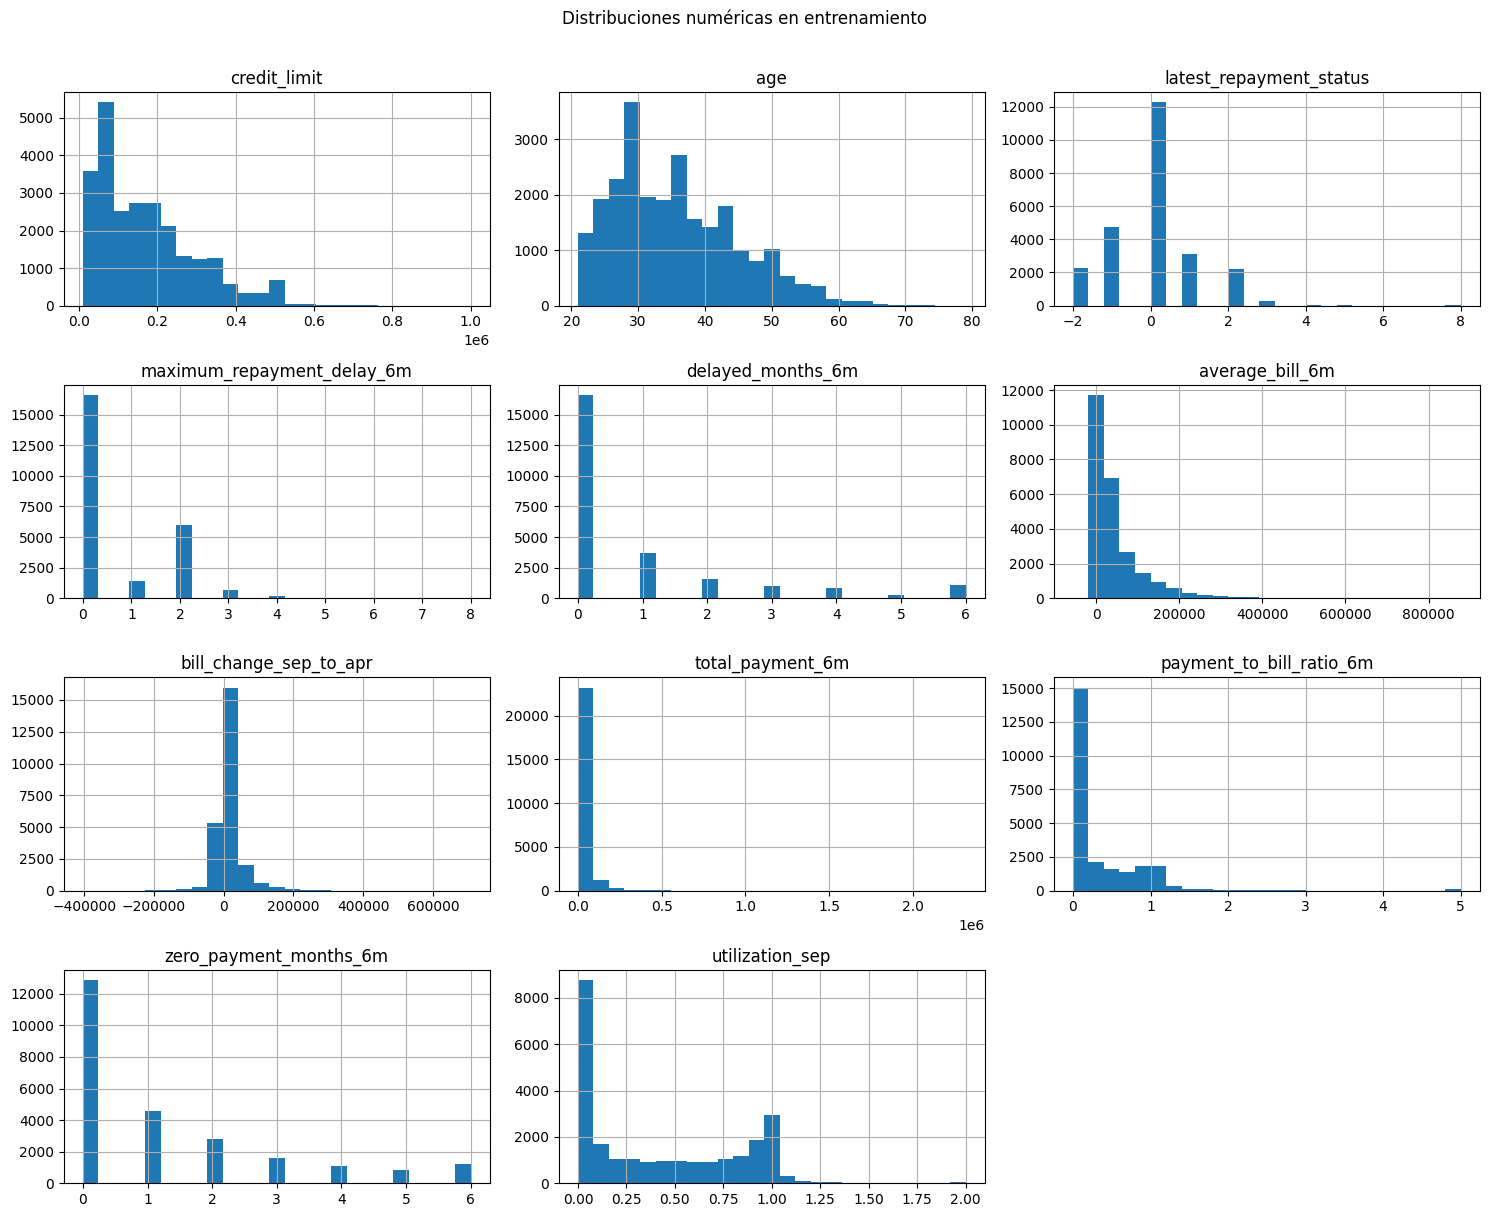

In [12]:
numeric_summary = X_raw[numeric_features].describe().T
display(numeric_summary.round(2))

X_raw[numeric_features].hist(bins=25, figsize=(15, 12), layout=(-1, 3))
plt.suptitle("Distribuciones numéricas en entrenamiento", y=1.01)
plt.tight_layout()
plt.show()

Los histogramas muestran asimetría hacia valores altos en varios importes monetarios. Por ejemplo, `total_payment_6m` tiene una mediana de **14.400 NTD**, una media de **31.635,05 NTD** y un máximo de **2.314.200 NTD**; unos pocos importes elevados amplían considerablemente el rango. `average_bill_6m` presenta también una media (44.910,44 NTD) superior a su mediana (21.000 NTD). No se eliminarán estos extremos sin una justificación adicional.

Las escalas difieren mucho: `credit_limit` va de 10.000 a 1.000.000 NTD, mientras que `payment_to_bill_ratio_6m` va de 0 a 5. Esta diferencia deberá tenerse en cuenta al preparar la regresión logística regularizada. Las variables de retraso concentran numerosos registros en cero, y los códigos de `latest_repayment_status` abarcan de −2 a 8; no se asigna un significado adicional a sus códigos no positivos. Los valores negativos de facturación y de su cambio se mantienen, pues estas comprobaciones no demuestran que sean errores.

Para las variables categóricas se muestran todos los niveles y sus frecuencias, incluyendo los ausentes si los hubiera. Las categorías con pocos registros pueden dar lugar a estimaciones menos estables; cualquier agrupación posterior deberá justificarse y evaluarse dentro de la validación cruzada.

In [13]:
categorical_tables = []
for column in categorical_features:
    counts = X_raw[column].value_counts(dropna=False)
    table = counts.rename_axis("Categoría").reset_index(name="Registros")
    table.insert(0, "Variable", column)
    table["Porcentaje"] = (table["Registros"] / len(X_raw) * 100).round(2)
    categorical_tables.append(table)

categorical_summary = pd.concat(categorical_tables, ignore_index=True)
display(categorical_summary)

,Variable,Categoría,Registros,Porcentaje
0,sex,female,15130,60.52
1,sex,male,9870,39.48
2,education,university,11675,46.70
3,education,graduate_school,8820,35.28
4,education,high_school,4107,16.43
5,education,unknown,289,1.16
6,education,other,109,0.44
7,marital_status,single,13310,53.24
8,marital_status,married,11368,45.47
9,marital_status,other_or_unknown,322,1.29


La categoría `female` representa el **60,52 %** de los registros y `male` el 39,48 %. En educación predominan `university` (46,70 %) y `graduate_school` (35,28 %); los niveles `unknown` (289 registros, 1,16 %) y `other` (109 registros, 0,44 %) son menos frecuentes. En estado civil, `other_or_unknown` reúne 322 registros (1,29 %).

El plan de asistencia está registrado en **5.320 casos (21,28 %)**. Los niveles menos frecuentes deberán tenerse en cuenta al interpretar resultados, pues disponen de menos observaciones. Por ahora se mantienen las categorías originales; no se agrupan a partir de sus frecuencias sin evaluar esa decisión.

### <a id="sec-3-6"></a> 3.6. Asociaciones y variables relacionadas

Se muestran las tasas observadas de dificultad de pago por categoría del plan de asistencia y del sexo registrado, junto al tamaño de cada grupo. Son asociaciones descriptivas sin ajuste por otras variables. La asignación selectiva del plan puede explicar diferencias entre sus grupos; las diferencias por sexo no bastan para concluir equidad o inequidad, y aún no son tasas de error de un modelo.

También se presentan los diez pares de variables numéricas con mayor correlación absoluta de Spearman. Esta medida resume asociaciones monótonas y resulta útil para reconocer información compartida entre resúmenes del comportamiento de pago. Una correlación alta no demuestra causalidad ni obliga a eliminar una variable; puede afectar a la estabilidad de los coeficientes y a cómo se reparte la importancia entre predictores.

In [14]:
association_tables = []
for column in ["repayment_assistance_plan", "sex"]:
    table = train_raw.groupby(column, dropna=False)[TARGET].agg(
        Registros="size", Casos_positivos="sum", Tasa_positiva="mean"
    ).reset_index().rename(columns={column: "Categoría"})
    table.insert(0, "Variable", column)
    table["Tasa positiva (%)"] = (table.pop("Tasa_positiva") * 100).round(2)
    association_tables.append(table)
display(pd.concat(association_tables, ignore_index=True))

spearman_corr = X_raw[numeric_features].corr(method="spearman")
upper_triangle = np.triu(np.ones(spearman_corr.shape, dtype=bool), k=1)
correlation_pairs = spearman_corr.where(upper_triangle).stack().rename("Spearman").reset_index()
correlation_pairs.columns = ["Variable 1", "Variable 2", "Spearman"]
correlation_pairs["Magnitud"] = correlation_pairs["Spearman"].abs()
display(correlation_pairs.sort_values("Magnitud", ascending=False).head(10).round(3))

,Variable,Categoría,Registros,Casos_positivos,Tasa positiva (%)
0,repayment_assistance_plan,no,19680,3565,18.11
1,repayment_assistance_plan,yes,5320,1738,32.67
2,sex,female,15130,3150,20.82
3,sex,male,9870,2153,21.81


,Variable 1,Variable 2,Spearman,Magnitud
27,maximum_repayment_delay_6m,delayed_months_6m,0.982,0.982
44,average_bill_6m,utilization_sep,0.747,0.747
20,latest_repayment_status,delayed_months_6m,0.647,0.647
53,payment_to_bill_ratio_6m,utilization_sep,-0.609,0.609
19,latest_repayment_status,maximum_repayment_delay_6m,0.607,0.607
41,average_bill_6m,total_payment_6m,0.598,0.598
50,total_payment_6m,zero_payment_months_6m,-0.517,0.517
42,average_bill_6m,payment_to_bill_ratio_6m,-0.515,0.515
43,average_bill_6m,zero_payment_months_6m,-0.507,0.507
24,latest_repayment_status,payment_to_bill_ratio_6m,-0.473,0.473


La tasa observada de dificultad de pago es del **32,67 % con plan de asistencia** y del **18,11 % sin plan**, una diferencia de 14,56 puntos porcentuales. La asociación es compatible con que el plan se ofrezca a clientes con señales previas de dificultad; **no demuestra que la asistencia cause un mayor riesgo**. Las tasas por sexo registrado son 20,82 % para `female` y 21,81 % para `male`. La diferencia descriptiva de 0,99 puntos porcentuales no constituye una evaluación de equidad ni de errores del modelo.

La correlación más elevada es la de `maximum_repayment_delay_6m` con `delayed_months_6m` (**Spearman = 0,982**), lo que muestra una relación monótona muy fuerte entre estos dos resúmenes del retraso. También destaca `average_bill_6m` con `utilization_sep` (0,747). Entre las asociaciones negativas figura `payment_to_bill_ratio_6m` con `utilization_sep` (−0,609). Esta información compartida deberá considerarse al interpretar coeficientes e importancias; no se seleccionan ni descartan variables con esta tabla.

### <a id="sec-3-7"></a> 3.7. Revisión de posibles fugas de información

La fuga de información aparece cuando el entrenamiento o la evaluación utilizan información que no estaría disponible al realizar la predicción. La correlación con el objetivo, por sí sola, no permite detectarla: hay que revisar el papel y la disponibilidad temporal de las variables.

| Elemento | Revisión y criterio de uso |
| --- | --- |
| `row_id` | Identificador opaco sin significado predictivo documentado. Se excluye de las entradas de los modelos y se conserva para alinear la exportación. |
| `payment_difficulty_next_month` y `predicted_class` | El objetivo y la salida de entrega no pueden formar parte de los predictores. |
| Resúmenes de pagos, facturas y retrasos | El diccionario los sitúa en los seis meses anteriores al resultado. Su uso presupone que esos resúmenes están disponibles en el momento de predecir. |
| `repayment_assistance_plan` | Se registra antes del mes del resultado según el diccionario. No se excluye automáticamente por su relación con la dificultad; debe distinguirse la disponibilidad temporal de la asignación selectiva y la interpretación causal. |
| Identificadores o perfiles repetidos | Si aparecen, se revisará si reflejan registros relacionados que podrían quedar repartidos entre entrenamiento y validación. Los predictores coincidentes no identifican por sí solos a una persona. |
| Preprocesamiento y selección | La imputación, codificación, escalado y cualquier transformación aprendida se ajustarán dentro de cada partición de entrenamiento. Las decisiones sobre variables, configuraciones y umbrales se evaluarán mediante validación cruzada. |
| Test sin etiquetas | Se reserva para la predicción final. Las comprobaciones de integridad no se utilizarán para ajustar el modelo o escoger transformaciones. |

La siguiente comprobación confirma la exclusión del identificador, el objetivo y la columna de entrega. La revisión temporal se basa en el diccionario; las comprobaciones de código no prueban por sí solas la ausencia de toda fuga de información.

In [15]:
excluded_columns = {ID_COLUMN, TARGET, PREDICTION_COLUMN}
leaked_columns = excluded_columns.intersection(X_raw.columns)
if leaked_columns:
    raise ValueError(f"Columnas que deben excluirse de los predictores: {sorted(leaked_columns)}")
if list(X_raw.columns) != list(X_test_raw.columns):
    raise ValueError("El orden de predictores no coincide entre entrenamiento y test.")
print("Identificador, objetivo y salida de entrega excluidos de los predictores.")
print("Mismo orden de columnas predictoras en entrenamiento y test.")

Identificador, objetivo y salida de entrega excluidos de los predictores.
Mismo orden de columnas predictoras en entrenamiento y test.


La comprobación confirma que `row_id`, `payment_difficulty_next_month` y `predicted_class` no están en los predictores, y que entrenamiento y test utilizan el mismo orden de columnas. Junto con la revisión temporal del diccionario, esto respalda la estructura actual de las entradas. Sigue siendo necesario ajustar las transformaciones dentro de cada partición de entrenamiento y evitar que las decisiones metodológicas utilicen el test; estas condiciones se desarrollarán en los apartados 4 y 5.

### <a id="sec-3-8"></a> 3.8. Síntesis de la exploración

Los datos presentan un desequilibrio de clases, pero no se han detectado ausentes, infinitos ni incumplimientos de los dominios comprobados. Se conservan todos los registros y variables candidatos. Los aspectos que requieren atención en las siguientes etapas son los perfiles repetidos, las categorías poco frecuentes, las diferencias de escala y los extremos monetarios, así como la fuerte correlación entre algunos resúmenes del retraso.

La evaluación deberá reflejar el rendimiento en ambas clases. El preprocesamiento se ajustará dentro de la validación cruzada y se adaptará a cada familia de modelos. Las explicaciones deberán considerar la información compartida entre variables y la asignación selectiva del plan de asistencia. Estos hallazgos describen el conjunto analizado; no permiten afirmar causalidad ni certificar su representatividad para una población real de crédito.

[Volver al índice](#indice)

## <a id="sec-4"></a> 4. Diseño de la evaluación

El protocolo se define antes de entrenar los modelos para que las tres familias se comparen bajo las mismas condiciones. Se utiliza únicamente el conjunto etiquetado. El test sin etiquetas se reserva para la predicción final.

### <a id="sec-4-1"></a> 4.1. Cinco particiones comunes

Se emplean **cinco particiones externas**, con una proporción aproximada del 80 % para entrenamiento y del 20 % para validación en cada una. Cada registro se utiliza una vez para validar y cuatro veces para entrenar. Se busca mantener una proporción de clases similar a la del conjunto completo.

Los perfiles de predictores repetidos detectados en el apartado 3 se mantienen en la misma partición mediante `StratifiedGroupKFold`. El grupo se define por la combinación de los 15 predictores originales, sin utilizar la etiqueta ni el identificador. Es una medida conservadora para evitar evaluar sobre un perfil idéntico al usado para entrenar; no presupone que los registros correspondan a la misma persona. Al respetar los grupos, los tamaños y proporciones pueden diferir ligeramente entre particiones.

Las particiones se generan una sola vez con `SEED = 42` y se guardan en `cv_splits` para reutilizarlas en todos los modelos. La tabla permite revisar el reparto y confirma que no hay perfiles compartidos entre entrenamiento y validación.

In [16]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

N_SPLITS = 5

# Los perfiles idénticos reciben el mismo grupo; la etiqueta no interviene.
profile_groups, unique_profiles = pd.factorize(pd.MultiIndex.from_frame(X_raw))
outer_cv = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cv_splits = list(outer_cv.split(X_raw, y, groups=profile_groups))

fold_rows = []
validation_coverage = np.zeros(len(y), dtype=int)
for fold, (train_idx, valid_idx) in enumerate(cv_splits, start=1):
    shared_profiles = np.intersect1d(profile_groups[train_idx], profile_groups[valid_idx])
    if len(shared_profiles):
        raise ValueError(f"Hay perfiles compartidos en la partición {fold}.")
    if y.iloc[train_idx].nunique() != 2 or y.iloc[valid_idx].nunique() != 2:
        raise ValueError(f"Falta una clase en la partición {fold}.")
    validation_coverage[valid_idx] += 1
    fold_rows.append({
        "Partición": fold,
        "Registros de entrenamiento": len(train_idx),
        "Registros de validación": len(valid_idx),
        "Clase 1 en entrenamiento (%)": round(y.iloc[train_idx].mean() * 100, 2),
        "Clase 1 en validación (%)": round(y.iloc[valid_idx].mean() * 100, 2),
        "Perfiles compartidos": len(shared_profiles),
    })

if not np.all(validation_coverage == 1):
    raise ValueError("Cada registro debe aparecer exactamente una vez en validación.")
fold_summary = pd.DataFrame(fold_rows)
display(fold_summary)
print(f"Perfiles distintos: {len(unique_profiles)} | Registros: {len(y)}")
print("Cada registro aparece exactamente una vez en validación.")

,Partición,Registros de entrenamiento,Registros de validación,Clase 1 en entrenamiento (%),Clase 1 en validación (%),Perfiles compartidos
0,1,19996,5004,21.04,21.90,0
1,2,20003,4997,21.13,21.55,0
2,3,19998,5002,21.23,21.13,0
3,4,20001,4999,21.35,20.66,0
4,5,20002,4998,21.31,20.81,0


Perfiles distintos: 24969 | Registros: 25000
Cada registro aparece exactamente una vez en validación.


Las cinco validaciones contienen entre **4.997 y 5.004 registros**, por lo que el reparto es prácticamente 80/20. La proporción de clase 1 en validación varía entre **20,66 % y 21,90 %**, próxima al 21,21 % del conjunto completo. La estratificación por grupos aproxima las proporciones sin hacerlas idénticas.

Se identifican **24.969 perfiles distintos en 25.000 registros**, en coherencia con las 31 repeticiones detectadas en la exploración. No hay perfiles compartidos entre entrenamiento y validación en ninguna partición, ambas clases están presentes y cada registro se utiliza exactamente una vez para validar. El reparto cumple las comprobaciones previstas y se conserva para comparar los tres modelos.

### <a id="sec-4-2"></a> 4.2. Métricas y criterio de selección

La clase positiva es **1: dificultad de pago**. Se registran las siguientes métricas:

| Métrica | Qué mide | Papel en la evaluación |
| --- | --- | --- |
| ROC-AUC | Capacidad de ordenar los casos positivos por encima de los negativos a partir de sus probabilidades. | Criterio principal para seleccionar configuraciones, porque permite comparar la discriminación sin fijar un umbral. No mide la calibración de las probabilidades. |
| Exactitud (*accuracy*) | Proporción total de etiquetas correctas. | Se incluye por su relación con la evaluación del test, pero se compara con la referencia mayoritaria del 78,79 %. |
| Exactitud equilibrada (*balanced accuracy*) | Media de la sensibilidad de la clase 1 y la de la clase 0. | Da el mismo peso a ambas clases y será el criterio para ajustar el umbral. |
| Sensibilidad (*recall*) | Proporción de casos reales de dificultad que se detectan. | Permite valorar los falsos negativos. |
| Precisión (*precision*) | Proporción de casos realmente positivos entre los clasificados como positivos. | Permite valorar cuántas alertas corresponden a dificultad real. |
| F1 | Media armónica de precisión y sensibilidad de la clase 1. | Resume el equilibrio entre detección y precisión, sin sustituir el análisis de ambas. |

La configuración de cada familia se seleccionará por la **mayor media de ROC-AUC en la validación interna**. Si hay empate exacto, se preferirá una configuración más sencilla conforme a la complejidad propia del modelo, dejando explícito el criterio en su apartado. Las diferencias pequeñas se interpretarán junto a la variabilidad entre particiones; la desviación típica no se tomará como una prueba de significación.

Para las métricas que requieren etiquetas se usa inicialmente un umbral de 0,5. Si no se predice ningún positivo, precisión y F1 se registran como cero mediante `zero_division=0`. El diccionario `SCORING` se utilizará en la referencia y en las búsquedas internas; en la evaluación externa del modelo ajustado, las métricas de etiquetas se calcularán con el umbral elegido dentro del entrenamiento correspondiente.

In [17]:
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score

SCORING = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "f1": make_scorer(f1_score, pos_label=1, zero_division=0),
}
PRIMARY_METRIC = "roc_auc"
THRESHOLD_METRIC = "balanced_accuracy"
DEFAULT_THRESHOLD = 0.5
THRESHOLD_GRID = np.round(np.arange(0.05, 1.00, 0.05), 2)

print("Criterio de selección de configuraciones:", PRIMARY_METRIC)
print("Criterio de selección del umbral:", THRESHOLD_METRIC)
print("Umbrales candidatos:", THRESHOLD_GRID)

Criterio de selección de configuraciones: roc_auc
Criterio de selección del umbral: balanced_accuracy
Umbrales candidatos: [0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7
 0.75 0.8  0.85 0.9  0.95]


Quedan fijados ROC-AUC como criterio para seleccionar configuraciones y exactitud equilibrada para seleccionar el umbral. La rejilla contiene **19 umbrales, de 0,05 a 0,95 en pasos de 0,05**, incluyendo 0,5 como referencia. Es una búsqueda acotada: el umbral elegido será el mejor entre esos candidatos según la validación interna, no necesariamente el óptimo entre todos los valores posibles. Esta celda define los criterios; todavía no selecciona ningún umbral.

### <a id="sec-4-3"></a> 4.3. Referencia de la clase mayoritaria

Se evalúa un `DummyClassifier` que aprende la clase mayoritaria únicamente en el entrenamiento de cada partición y la predice para todos sus registros de validación. Esta referencia permite comprobar qué aporta cada modelo frente a una regla que ignora los predictores. Se presentan sus cinco resultados y su media y desviación típica muestral.

Si todos los entrenamientos mantienen la clase 0 como mayoritaria, la referencia tendrá sensibilidad, precisión y F1 de la clase positiva iguales a cero, y exactitud equilibrada y ROC-AUC de 0,5. La exactitud dependerá de la proporción de clase 0 en cada validación; superar esa cifra no será suficiente por sí solo para concluir que un modelo detecta bien la dificultad de pago.

In [18]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent", random_state=SEED)
baseline_cv = cross_validate(
    baseline, X_raw, y, cv=cv_splits, scoring=SCORING,
    n_jobs=N_JOBS, error_score="raise",
)
baseline_scores = pd.DataFrame({
    metric: baseline_cv[f"test_{metric}"] for metric in SCORING
})
baseline_scores.index = pd.Index(range(1, N_SPLITS + 1), name="Partición")
display(baseline_scores.round(4))

baseline_summary = pd.DataFrame({
    "Media": baseline_scores.mean(),
    "Desviación típica": baseline_scores.std(ddof=1),
})
display(baseline_summary.round(4))

,roc_auc,accuracy,balanced_accuracy,recall,precision,f1
Partición,,,,,,
1,0.5,0.7810,0.5,0.0,0.0,0.0
2,0.5,0.7845,0.5,0.0,0.0,0.0
3,0.5,0.7887,0.5,0.0,0.0,0.0
4,0.5,0.7934,0.5,0.0,0.0,0.0
5,0.5,0.7919,0.5,0.0,0.0,0.0


,Media,Desviación típica
roc_auc,0.5000,0.0000
accuracy,0.7879,0.0052
balanced_accuracy,0.5000,0.0000
recall,0.0000,0.0000
precision,0.0000,0.0000
f1,0.0000,0.0000


La referencia obtiene una **exactitud media de 0,7879 (78,79 %)**, con desviación típica de 0,0052, equivalente a aproximadamente 0,52 puntos porcentuales. La variación entre particiones refleja sus ligeras diferencias en la proporción de clases.

En las cinco particiones, **ROC-AUC y exactitud equilibrada son 0,5**, mientras que sensibilidad, precisión y F1 de la clase positiva son cero. El clasificador predice siempre la clase 0 y no detecta ningún caso de dificultad de pago. Su exactitud relativamente alta se explica por el desequilibrio de clases, lo que respalda la necesidad de examinar las demás métricas. Los modelos se compararán con esta referencia usando las mismas particiones.

### <a id="sec-4-4"></a> 4.4. Ajuste de configuraciones, variables y umbrales

Se utiliza **validación cruzada anidada**: las cinco particiones externas estiman el rendimiento del procedimiento completo y, dentro del entrenamiento de cada una, otras cinco particiones internas permiten tomar decisiones. Así, los registros de validación externa no intervienen en la selección de configuraciones o del umbral.

Para cada familia y cada partición externa se seguirá este procedimiento:

1. Construir cinco particiones internas utilizando únicamente los registros de entrenamiento externo y manteniendo juntos los perfiles idénticos.
2. Comparar una búsqueda acotada de configuraciones mediante ROC-AUC interna. Si se prueban subconjuntos de variables o transformaciones, su selección formará parte de esta búsqueda. La imputación, codificación y el escalado se ajustarán en el entrenamiento de cada partición mediante un pipeline.
3. Con la configuración elegida, obtener probabilidades *fuera de muestra* (*out-of-fold*, OOF) en las particiones internas: cada registro recibe una probabilidad de un modelo que no lo utilizó para entrenar. Probar los umbrales de `THRESHOLD_GRID` y elegir el de mayor media de exactitud equilibrada entre las cinco validaciones internas. En caso de empate, escoger el más cercano a 0,5 y, si persiste, el menor. Se predice clase 1 cuando `probabilidad >= umbral`.
4. Reentrenar la configuración elegida con todo el entrenamiento externo y evaluar una única vez sobre su validación externa. Registrar ROC-AUC con las probabilidades y las métricas de clasificación con el umbral interno elegido; conservar también las métricas con 0,5 para mostrar el efecto del ajuste.
5. Repetir el proceso en las cinco particiones externas, guardando configuraciones, umbrales y predicciones externas OOF.

Las métricas internas sirven para seleccionar y pueden ser optimistas al reutilizarse en esa selección; las métricas externas evalúan las decisiones realizadas sin consultar su validación. Esta separación aumenta el coste de entrenamiento, por lo que las búsquedas se limitarán a opciones justificadas para cada modelo.

La siguiente función prepara las particiones internas a partir de los índices de entrenamiento externo. Se utilizará al desarrollar los modelos; todavía no realiza búsquedas ni entrenamiento.

In [19]:
def make_inner_splits(outer_train_idx):
    """Devuelve índices relativos al subconjunto de entrenamiento externo."""
    inner_X = X_raw.iloc[outer_train_idx]
    inner_y = y.iloc[outer_train_idx]
    inner_groups = profile_groups[outer_train_idx]
    inner_cv = StratifiedGroupKFold(
        n_splits=N_SPLITS, shuffle=True, random_state=SEED
    )
    inner_splits = list(inner_cv.split(inner_X, inner_y, groups=inner_groups))
    for train_idx, valid_idx in inner_splits:
        if len(np.intersect1d(inner_groups[train_idx], inner_groups[valid_idx])):
            raise ValueError("Hay perfiles compartidos en una partición interna.")
        if inner_y.iloc[train_idx].nunique() != 2 or inner_y.iloc[valid_idx].nunique() != 2:
            raise ValueError("Falta una clase en una partición interna.")
    return inner_splits

Esta celda define la función y no genera salida. Las particiones internas y sus comprobaciones se ejecutarán cuando se llame a `make_inner_splits` durante el desarrollo de cada modelo. Por tanto, las salidas actuales verifican el reparto externo y la referencia mayoritaria, pero todavía no verifican los repartos internos ni ofrecen resultados de selección de modelos.

### <a id="sec-4-5"></a> 4.5. Comparación y entrenamiento final

La comparación mostrará, para cada familia, las métricas de sus cinco validaciones externas, su media y desviación típica, y las configuraciones y umbrales seleccionados. Se utilizarán las mismas particiones para comparar los resultados de forma emparejada. Los hiperparámetros elegidos pueden variar entre entrenamientos externos: se está evaluando un procedimiento de selección, no una única configuración fijada de antemano.

Se partirá del rendimiento externo en ROC-AUC y se examinarán también la exactitud equilibrada, F1, precisión y sensibilidad, junto con la complejidad y la claridad de las explicaciones. Si los resultados predictivos son próximos, se justificará la preferencia por una representación más sencilla e interpretable. La selección de la familia a partir de estos resultados implica que la estimación de la familia ganadora todavía puede ser optimista; no se presentará como una evaluación final independiente.

Una vez elegida la familia, el apartado 12 repetirá la búsqueda de cinco particiones sobre **todos los datos etiquetados**, usando los mismos candidatos y criterios definidos para esa familia. Su configuración y umbral finales se seleccionarán con esa validación y las probabilidades OOF correspondientes; después se ajustará el modelo con todos los registros. En el apartado 13 se aplicará al test sin modificar sus filas ni columnas originales, añadiendo únicamente `predicted_class`. El test no participará en la selección ni podrá proporcionar métricas locales porque no incluye etiquetas.

[Volver al índice](#indice)

## <a id="sec-5"></a> 5. Preprocesamiento

El preprocesamiento adapta las entradas a cada familia de modelos y conserva los nombres de las variables para interpretar sus resultados. Se mantienen los registros, las categorías y los valores extremos originales. El identificador y la variable objetivo ya están separados de los predictores.

### <a id="sec-5-1"></a> 5.1. Decisiones de preprocesamiento

| Familia | Variables numéricas | Variables categóricas | Valores ausentes |
| --- | --- | --- | --- |
| Modelo lógico basado en árbol | Sin escalado. | One-hot con todas las categorías observadas en entrenamiento. | Mediana en numéricas y categoría más frecuente en categóricas. |
| Regresión logística | Estandarización: restar la media y dividir por la desviación típica del entrenamiento. | One-hot con una categoría de referencia por variable. | Mediana en numéricas y categoría más frecuente en categóricas, antes de codificar o escalar. |
| EBM | Valores originales; el modelo aprende su propia discretización. | Categorías originales, sin one-hot. | Tratamiento nativo de EBM, sin imputación externa. |

No se observaron ausentes en los archivos actuales. La imputación de árbol y regresión logística se incluye como tratamiento explícito para posibles ausentes posteriores; no modifica los valores presentes ni garantiza buen rendimiento si aparecen patrones nuevos de ausencia. EBM dispone de un tratamiento propio de ausentes, por lo que se conservan si aparecen.

Los niveles `unknown` y `other_or_unknown` se mantienen como categorías documentadas. No se agrupan niveles poco frecuentes, no se recortan extremos ni se aplican logaritmos. Una modificación posterior de estas decisiones deberá justificarse y evaluarse dentro de la búsqueda interna.

`latest_repayment_status` se mantiene inicialmente como variable numérica, sin inventar significados para los códigos no positivos. En regresión logística, este tratamiento supone una relación lineal del código con los log-odds, que deberá considerarse al interpretar sus coeficientes; una codificación alternativa, si se prueba, se evaluará dentro de la validación interna.

### <a id="sec-5-2"></a> 5.2. Codificación y escalado

La codificación one-hot evita asignar un orden artificial a variables como educación o estado civil. Para el árbol se conservan todas las categorías. Para la regresión logística se elimina la primera categoría, ordenada por el codificador, como referencia; sus coeficientes se interpretarán respecto a esa categoría. Esta es una elección inicial de representación y no implica que sea la mejor para todas las configuraciones de regularización.

Se utiliza `handle_unknown="ignore"`: una categoría no vista durante el entrenamiento se representa con ceros en las columnas de esa variable. Así se evita un error al transformar la validación, pero no se aprende un efecto específico para la nueva categoría. En regresión logística esa representación coincide con la referencia y debe tenerse en cuenta al interpretar una predicción.

`StandardScaler` se aplica solo a las numéricas de regresión logística, para que la penalización no dependa de sus diferencias de escala. Los árboles dividen por umbrales y EBM aprende intervalos de cada variable, por lo que no se escalan sus entradas. Las columnas binarias one-hot se mantienen como 0 y 1.

La función siguiente construye transformadores **sin ajustar**. Devuelven DataFrames con nombres de columnas; el formato denso es adecuado para el reducido número de categorías de este conjunto. La selección opcional de variables se expresa con sus nombres originales y no aprende ningún subconjunto automáticamente.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_preprocessor(family, selected_features=None):
    """Construye el preprocesamiento; todavía no aprende ningún parámetro."""
    if family not in ("tree", "logistic", "ebm"):
        raise ValueError("Familia no reconocida: usa tree, logistic o ebm.")
    columns = list(feature_columns if selected_features is None else selected_features)
    if not columns or len(columns) != len(set(columns)):
        raise ValueError("Selecciona al menos una variable y evita nombres repetidos.")
    unknown_columns = set(columns) - set(feature_columns)
    if unknown_columns:
        raise ValueError(f"Variables no disponibles: {sorted(unknown_columns)}")
    num_columns = [column for column in columns if column in numeric_features]
    cat_columns = [column for column in columns if column in categorical_features]

    if family == "ebm":
        # Selecciona las columnas en su orden original, conservando sus tipos.
        transformations = [("original", "passthrough", columns)]
    else:
        numeric_steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
        if family == "logistic":
            numeric_steps.append(("scaler", StandardScaler()))
        categorical_steps = [
            ("imputer", SimpleImputer(strategy="most_frequent", keep_empty_features=True)),
            ("encoder", OneHotEncoder(
                drop="first" if family == "logistic" else None,
                handle_unknown="ignore", sparse_output=False,
            )),
        ]
        transformations = [
            ("numeric", Pipeline(numeric_steps), num_columns),
            ("categorical", Pipeline(categorical_steps), cat_columns),
        ]

    return ColumnTransformer(
        transformations, remainder="drop", verbose_feature_names_out=False
    ).set_output(transform="pandas")

### <a id="sec-5-3"></a> 5.3. Integración con los modelos

Cada pipeline contiene un paso `preprocess` y otro `model`. Al ajustarlo en una partición, se aprenden primero los parámetros del preprocesamiento con sus registros de entrenamiento y después se entrena el modelo con esas entradas. Al predecir sobre validación se reutilizan los parámetros aprendidos, sin volver a ajustarlos.

Las funciones crean pipelines nuevos para evitar compartir transformadores ya ajustados. La regresión logística utiliza inicialmente regularización L2 y `liblinear`, una configuración compatible con este problema binario; su regularización y demás configuraciones se evaluarán en el apartado 7. EBM se construye con `interactions=0`, como exige el proyecto. Los parámetros iniciales no son configuraciones seleccionadas ni resultados de entrenamiento.

Los hiperparámetros del modelo se identificarán con el prefijo `model__` en las búsquedas, por ejemplo `model__max_depth`, `model__C` o `model__max_bins`. Si se incorporan otros modelos lógicos, se revisarán sus requisitos de representación antes de reutilizar el preprocesamiento del árbol.

In [21]:
def make_tree_pipeline(selected_features=None, **model_params):
    params = {"random_state": SEED, **model_params}
    return Pipeline([
        ("preprocess", make_preprocessor("tree", selected_features)),
        ("model", DecisionTreeClassifier(**params)),
    ])


def make_logistic_pipeline(selected_features=None, **model_params):
    params = {
        "random_state": SEED, "penalty": "l2", "solver": "liblinear",
        "max_iter": 2000, **model_params,
    }
    return Pipeline([
        ("preprocess", make_preprocessor("logistic", selected_features)),
        ("model", LogisticRegression(**params)),
    ])


def make_ebm_pipeline(selected_features=None, **model_params):
    if model_params.get("interactions", 0) != 0:
        raise ValueError("El EBM del proyecto debe utilizar interactions=0.")
    params = {"random_state": SEED, "n_jobs": N_JOBS, **model_params, "interactions": 0}
    return Pipeline([
        ("preprocess", make_preprocessor("ebm", selected_features)),
        ("model", ExplainableBoostingClassifier(**params)),
    ])


tree_pipeline = make_tree_pipeline()
logistic_pipeline = make_logistic_pipeline()
ebm_pipeline = make_ebm_pipeline()

for name, pipeline in (
    ("Árbol", tree_pipeline), ("Regresión logística", logistic_pipeline), ("EBM", ebm_pipeline)
):
    print(f"{name}: {type(pipeline['preprocess']).__name__} → {type(pipeline['model']).__name__}")
print("Pipelines creados sin ajustar ni entrenar modelos.")

Árbol: ColumnTransformer → DecisionTreeClassifier
Regresión logística: ColumnTransformer → LogisticRegression
EBM: ColumnTransformer → ExplainableBoostingClassifier
Pipelines creados sin ajustar ni entrenar modelos.


### <a id="sec-5-4"></a> 5.4. Comprobación en una partición

Para observar las transformaciones se utiliza el entrenamiento de la primera partición externa. Se ajustan **copias independientes de los preprocesadores**, sin entrenar modelos ni modificar los pipelines anteriores. Se transforma después su validación y se comprueba que tenga las mismas columnas y conserve su índice. La tabla muestra la dimensión de cada representación.

Esta demostración no se utilizará como entrada de las búsquedas posteriores: cada pipeline volverá a aprender su preprocesamiento dentro del entrenamiento interno correspondiente. Ajustar aquí un transformador y reutilizar sus resultados en toda la validación interna introduciría fuga de información.

In [22]:
from sklearn.base import clone

example_train_idx, example_valid_idx = cv_splits[0]
example_X_train = X_raw.iloc[example_train_idx]
example_X_valid = X_raw.iloc[example_valid_idx]
demo_preprocessors = {}
demo_train_data = {}
preprocessing_rows = []

for name, pipeline in (
    ("Árbol", tree_pipeline), ("Regresión logística", logistic_pipeline), ("EBM", ebm_pipeline)
):
    preprocessor = clone(pipeline["preprocess"])
    transformed_train = preprocessor.fit_transform(example_X_train)
    transformed_valid = preprocessor.transform(example_X_valid)
    if list(transformed_train.columns) != list(transformed_valid.columns):
        raise ValueError(f"Columnas diferentes entre entrenamiento y validación para {name}.")
    if not transformed_train.index.equals(example_X_train.index):
        raise ValueError(f"El índice de entrenamiento cambió para {name}.")
    if not transformed_valid.index.equals(example_X_valid.index):
        raise ValueError(f"El índice de validación cambió para {name}.")
    if name != "EBM" and not np.isfinite(transformed_valid.to_numpy()).all():
        raise ValueError(f"La representación de validación contiene ausentes o infinitos para {name}.")
    demo_preprocessors[name] = preprocessor
    demo_train_data[name] = transformed_train
    preprocessing_rows.append({
        "Familia": name,
        "Columnas originales": example_X_train.shape[1],
        "Columnas tras transformar": transformed_train.shape[1],
        "Filas de entrenamiento": len(transformed_train),
        "Filas de validación": len(transformed_valid),
        "Columnas e índices conservados en validación": True,
    })

display(pd.DataFrame(preprocessing_rows))

,Familia,Columnas originales,Columnas tras transformar,Filas de entrenamiento,Filas de validación,Columnas e índices conservados en validación
0,Árbol,15,23,19996,5004,True
1,Regresión logística,15,19,19996,5004,True
2,EBM,15,15,19996,5004,True


La siguiente salida muestra las categorías de referencia realmente aprendidas en este entrenamiento y cómo cambia la escala de las variables numéricas. Tras estandarizar, la media del entrenamiento debe estar próxima a cero y su desviación típica poblacional a uno para las variables no constantes. **La validación no tiene por qué cumplir esas cifras**, pues se transforma con los parámetros del entrenamiento.

In [23]:
logistic_demo = demo_preprocessors["Regresión logística"]
encoder_demo = logistic_demo.named_transformers_["categorical"].named_steps["encoder"]
reference_categories = pd.DataFrame({
    "Variable": categorical_features,
    "Categoría de referencia": [
        categories[drop_idx]
        for categories, drop_idx in zip(encoder_demo.categories_, encoder_demo.drop_idx_)
    ],
})
display(reference_categories)

scaling_demo = pd.DataFrame({
    "Media original": example_X_train[numeric_features].mean(),
    "Desviación original": example_X_train[numeric_features].std(ddof=0),
    "Media estandarizada": demo_train_data["Regresión logística"][numeric_features].mean(),
    "Desviación estandarizada": demo_train_data["Regresión logística"][numeric_features].std(ddof=0),
})
display(scaling_demo.round(4))

,Variable,Categoría de referencia
0,sex,female
1,education,graduate_school
2,marital_status,married
3,repayment_assistance_plan,no


,Media original,Desviación original,Media estandarizada,Desviación estandarizada
credit_limit,167360.1560,129678.6408,-0.0,1.0
age,35.4708,9.2304,0.0,1.0
latest_repayment_status,-0.0218,1.1215,0.0,1.0
maximum_repayment_delay_6m,0.6765,1.0678,0.0,1.0
delayed_months_6m,0.8274,1.5468,0.0,1.0
average_bill_6m,44873.2547,63102.0731,0.0,1.0
bill_change_sep_to_apr,12200.5251,44144.2507,-0.0,1.0
total_payment_6m,31819.5739,58798.8371,0.0,1.0
payment_to_bill_ratio_6m,0.3757,0.5940,-0.0,1.0
zero_payment_months_6m,1.2337,1.7219,0.0,1.0


### <a id="sec-5-5"></a> 5.5. Uso en la validación cruzada

En los apartados 6–8 se pasarán **los datos originales y el pipeline completo** a las búsquedas internas. No se codificará ni escalará todo `X_raw` antes de validar. Las categorías, valores de imputación, medias y desviaciones se aprenderán en el entrenamiento de cada partición, y las comprobaciones de rendimiento utilizarán su validación.

El número de columnas one-hot puede variar entre entrenamientos si alguno no incluye un nivel poco frecuente. Cada modelo conservará sus propios nombres de variables transformadas y sus referencias para interpretar coeficientes, reglas o explicaciones locales. EBM mantendrá las variables originales y aprenderá sus intervalos y categorías dentro de su propio ajuste.

La comprobación anterior permite inspeccionar la representación, pero todavía no ofrece resultados predictivos ni selecciona variables o configuraciones. Las observaciones concretas sobre sus dimensiones, referencias y escalado se incorporarán después de revisar las salidas.

[Volver al índice](#indice)

## <a id="sec-6"></a> 6. Modelo lógico

## <a id="sec-7"></a> 7. Regresión logística

## <a id="sec-8"></a> 8. Explainable Boosting Machine

## <a id="sec-9"></a> 9. Comparación del rendimiento

## <a id="sec-10"></a> 10. Interpretación local comparada

## <a id="sec-11"></a> 11. Discusión de las explicaciones

## <a id="sec-12"></a> 12. Selección y entrenamiento final

## <a id="sec-13"></a> 13. Predicción y exportación del test

## <a id="sec-14"></a> 14. Conclusiones

## <a id="sec-15"></a> 15. Referencias y uso de IA generativa